EDA Assignment: Does More Health Spending = Longer Life?
**Name:** Hamza Haroon |  **Date:** __________  |  ⏱️ *Target time: ~1 hour*

---
### 🤔 The big question
Every country spends money on healthcare — some spend *a lot* more than others. It seems obvious that **spending more should mean people live longer**... right?

**Your job:** use EDA to find out if that's actually true. This is an **open-ended** assignment — there's no single "correct" cell to fill in. You explore the data, follow what's interesting, and back up your answer with charts.

> 🎯 **Before you touch the data, write your gut guess here:**
> *Do you think the country that spends the MOST on healthcare also lives the longest? (yes / no / not sure):* Yes. It is a common assumption that more funding leads to better health outcomes and longer lifespans

**The dataset:** health spending per person vs life expectancy, for 6 wealthy countries, 1970–2020 (real OECD-style data, built into seaborn — loads offline).

### 📤 What to hand in
Answer every ✍️ **question** in your own words, and make sure your charts are clear (titles + labels). Marks reward **insight and evidence**, not fancy code. Run *Kernel → Restart & Run All* before submitting.

## Step 0 — Setup & Load *(warm-up)*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = sns.load_dataset('healthexp')   # Year, Country, Spending_USD, Life_Expectancy
print("Shape:", df.shape)
df.head()

Shape: (274, 4)


,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [2]:
# TODO: Get to know the data. Show:
#   - which countries are included  (HINT: df['Country'].unique())
#   - the range of years            (HINT: df['Year'].min(), df['Year'].max())
#   - a quick df.describe()

print("Countries included:", df['Country'].unique())
print("Range of years:", df['Year'].min(), "to", df['Year'].max())
display(df.describe())

Countries included: ['Germany' 'France' 'Great Britain' 'Japan' 'USA' 'Canada']
Range of years: 1970 to 2020


,Year,Spending_USD,Life_Expectancy
count,274.000000,274.000000,274.000000
mean,1996.992701,2789.338905,77.909489
std,14.180933,2194.939785,3.276263
min,1970.000000,123.993000,70.600000
25%,1985.250000,1038.357000,75.525000
50%,1998.000000,2295.578000,78.100000
75%,2009.000000,4055.610000,80.575000
max,2020.000000,11859.179000,84.700000


## Task 1 — The Core Relationship *(≈15 min)*
*Is there a link between how much a country spends and how long people live?*

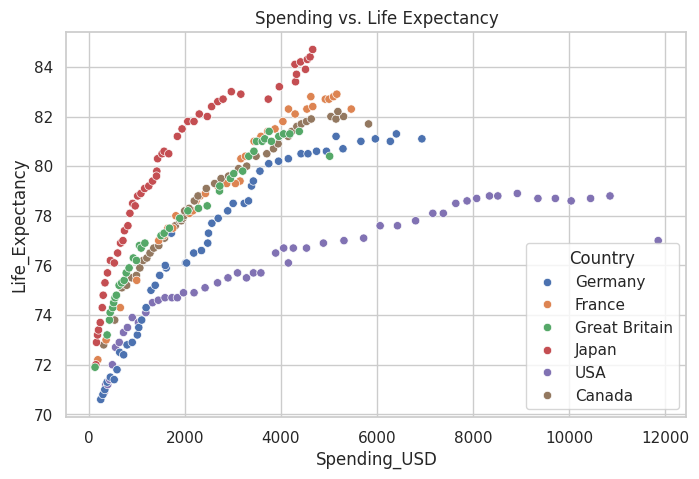

Correlation: 0.5794304588530952


In [5]:
# TODO: Make a scatter plot of Spending_USD (x) vs Life_Expectancy (y).
# Colour the points by Country so you can see who's who.
# HINT: sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')
plt.title("Spending vs. Life Expectancy")
plt.show()

# Checking the correlation just to be sure
print("Correlation:", df['Spending_USD'].corr(df['Life_Expectancy']))

**✍️ Q1:** In general, as spending goes up, does life expectancy go up, down, or stay flat? Would you call the relationship strong or weak?
*Your answer:* Generally, as spending goes up, life expectancy goes up. The relationship is positive and moderately strong the correlation is ~0.58. However, it is not perfectly linear; the benefits seem to curve off at higher spending levels.

*Optional hint for evidence:* `df['Spending_USD'].corr(df['Life_Expectancy'])` gives a number from −1 to +1.

## Task 2 — Find the Odd One Out *(≈15 min)*
*Every good analyst looks for what breaks the pattern.*

,Year,Country,Spending_USD,Life_Expectancy
273,2020,USA,11859.179,77.0
269,2020,Germany,6938.983,81.1
268,2020,Canada,5828.324,81.7
270,2020,France,5468.418,82.3
271,2020,Great Britain,5018.700,80.4
272,2020,Japan,4665.641,84.7


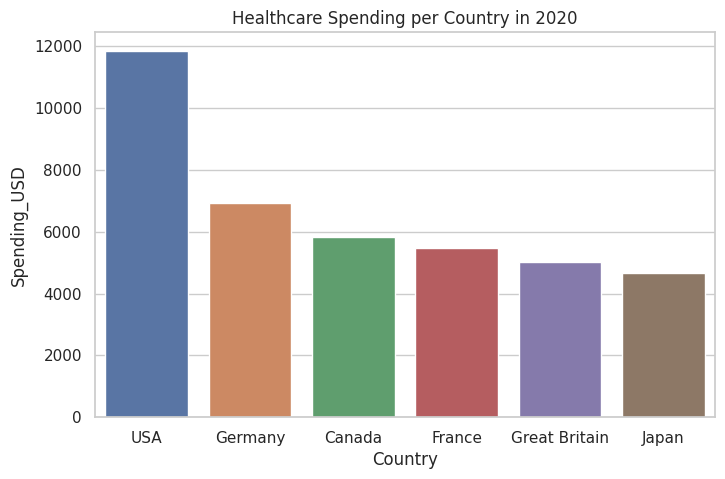

In [6]:
# TODO: Look at just the most recent year in the data.
# HINT: latest = df[df['Year'] == df['Year'].max()]
# Then sort by Spending_USD to see who spends the most vs who lives longest.
# A bar chart of spending per country (for that year) makes it obvious.

latest = df[df['Year'] == df['Year'].max()]
latest_sorted = latest.sort_values(by='Spending_USD', ascending=False)

# See who spends the most vs lives longest directly
display(latest_sorted)

# Bar chart of spending per country
plt.figure(figsize=(8, 5))
sns.barplot(data=latest_sorted, x='Country', y='Spending_USD', hue='Country')
plt.title("Healthcare Spending per Country in 2020")
plt.show()

**✍️ Q2:** Which country **spends the most** per person? Which country **lives the longest**? Are they the same country? *(This is the heart of the assignment — what surprised you?)*
*Your answer:* USA spends the most per person by far, but Japan lives the longest. They are not the same country. What surprised me is that the USA spends drastically more than the others, yet actually has the lowest life expectancy of the entire group in 2020.

## Task 3 — Change Over Time *(≈15 min)*
*Has the story always been this way, or did it change?*

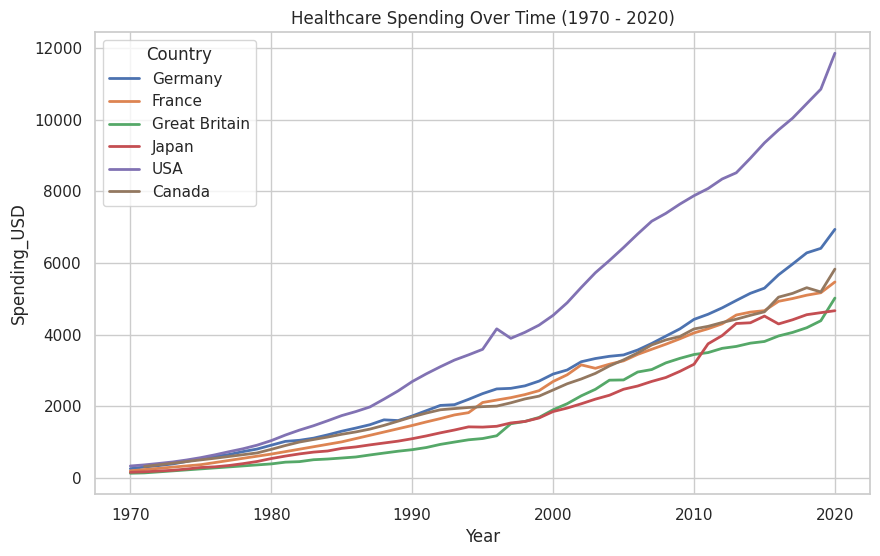

In [7]:
# TODO: Plot how ONE thing changed from 1970 to 2020, for every country.
# Pick either Spending_USD OR Life_Expectancy over Year, with one line per country.
# HINT: sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country', linewidth=2)
plt.title("Healthcare Spending Over Time (1970 - 2020)")
plt.show()

**✍️ Q3:** Describe one clear trend you see over time. Does one country pull away from the others at some point?
*Your answer:* Healthcare spending increases steadily for all countries over time. However, starting around the early 1990s, the USA pulls away dramatically from the rest of the group, with its spending skyrocketing compared to the relatively gradual increases of the other nations.

## Task 4 — Your Own Investigation *(≈10 min)*  🔍 *open-ended*
Ask **your own** question about this data and answer it with **one** chart. Ideas (or invent your own):
- Who improved their life expectancy the *most* since 1970?
- Which country gets the most "life expectancy per dollar" (best value)?
- Is any country's life expectancy *flattening* even as spending climbs?

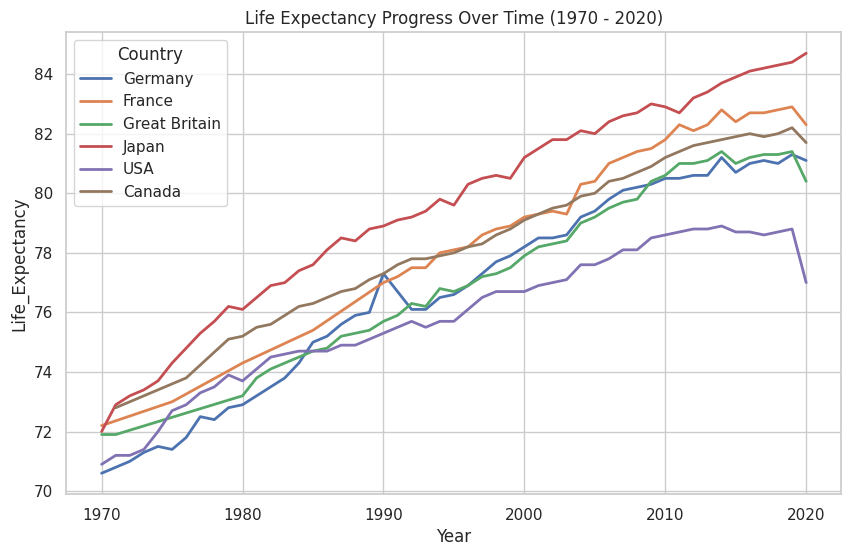

In [8]:
# TODO: Your question, your chart. Write your question as a comment first, then the code.
# My question: Is any country's life expectancy flattening even as spending climbs?

plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='Year', y='Life_Expectancy', hue='Country', linewidth=2)
plt.title("Life Expectancy Progress Over Time (1970 - 2020)")
plt.show()

**✍️ Q4:** What did *your* chart show? State your finding in one sentence.
*Your answer:* My chart showed that while most countries saw a continuous upward trend in life expectancy, the USA's life expectancy flattened around 2010 and notably dipped in 2020, despite their spending climbing exponentially during that time.

## 🏁 Your Verdict
Answer the assignment's big question in **2–3 sentences**, using what your charts showed. Then look back: **was your gut guess from the top right or wrong?**

**✍️ Final verdict:**

> The data reveals that while a foundational amount of spending is tied to higher life expectancy, simply throwing more money at healthcare does not equal longer lives. The United States vastly outspends every other country yet has the lowest life expectancy of the group, while nations like Japan achieve much longer lifespans for a fraction of the per-person cost.
>
> _______________________________________________

> *My original guess was (right / wrong) because: My original guess was wrong because: I logically assumed that the highest-spending country would have the best health outcomes, but the data proved that the USA breaks this pattern entirely by paying the most for the least years of life.

---
✅ *Before submitting:* every ✍️ answered, charts have titles/labels, ran Restart & Run All with no errors. Nice work! 🎉